# GEDI vs Sentinel-2 Validation — Hurricane Helene

This notebook compares GEDI-based canopy height damage labels against the Sentinel-2 binary damage labels already exported to GEE.

**Before running:**
- Make sure `gedi_labels_FINAL.csv` is in the same folder as this notebook
- Make sure GEE is authenticated (`ee.Authenticate()` if needed)
- Run cells top to bottom

**Outputs:**
- `confusion_matrix.png`
- `gedi_vs_s2_scatter.png`
- `agreement_map.png`
- `gedi_s2_comparison.csv`

In [ ]:
# ── Install dependencies if needed ───────────────────────────────────────────
%pip install earthengine-api geemap pandas numpy scikit-learn matplotlib seaborn -q

In [1]:
# ── Authenticate GEE (only needed once per machine) ──────────────────────────
import ee
ee.Authenticate()

c:\Users\jazmi\anaconda3\Lib\site-packages\google\api_core\_python_version_support.py:254: FutureWarning: You are using a Python version (3.11.4) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2027-10-24). Please upgrade to the latest Python version, or at least Python 3.12, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)
c:\Users\jazmi\anaconda3\Lib\site-packages\google\api_core\_python_package_support.py:206: FutureWarning: Package google.api_core depends on grpcio, currently installed at version 1.67.0. grpcio < 1.83.0 does not support Post-Quantum Cryptography (PQC). Support for non-PQC environments is deprecated. In April 2027, Google Cloud Python packages will raise their minimum requirements (including google-api-core, grpcio, and grpcio-status) to enforce grpcio >= 1.83.0. For more details on Google Cloud's post-quantum security migration, visit: https://cloud.google

True

In [2]:
# ── Imports ───────────────────────────────────────────────────────────────────
import ee
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# ── Initialize GEE ───────────────────────────────────────────────────────────
ee.Initialize(project="geospatialfinalproject")
print("GEE connected!")

c:\Users\jazmi\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.4' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
c:\Users\jazmi\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


GEE connected!


In [3]:
# ── Load GEE assets ───────────────────────────────────────────────────────────
folder = "projects/geospatialfinalproject/assets/Hurricane_Helene_BA"

inputs = ee.Image(f"{folder}/helene_21band_inputs")
labels = ee.Image(f"{folder}/helene_binary_labels").select("label")
tiles  = ee.FeatureCollection(f"{folder}/helene_valid_tiles")

print("Assets loaded.")
print("Input bands:", inputs.bandNames().getInfo())
print("Label bands:", labels.bandNames().getInfo())
print("Tiles:", tiles.size().getInfo())

Assets loaded.
Input bands: ['pre_B2', 'pre_B3', 'pre_B4', 'pre_B8', 'pre_B11', 'pre_B12', 'pre_NDVI', 'pre_NDMI', 'pre_NBR', 'post_B2', 'post_B3', 'post_B4', 'post_B8', 'post_B11', 'post_B12', 'post_NDVI', 'post_NDMI', 'post_NBR', 'NDVI_change', 'NDMI_change', 'NBR_change']
Label bands: ['label']
Tiles: 232


In [4]:
# ── Load GEDI labels ──────────────────────────────────────────────────────────
# gedi_labels_FINAL.csv must be in the same folder as this notebook
gedi = pd.read_csv("gedi_labels_FINAL.csv")

print(f"GEDI labels loaded: {len(gedi):,} grid cells")
print("\nLabel distribution:")
print(gedi["damage_label"].value_counts())
print("\nDelta rh98 stats:")
print(gedi["delta_rh98"].describe().round(2))

GEDI labels loaded: 3,601 grid cells

Label distribution:
damage_label
moderate    1169
gain         953
none         946
high         533
Name: count, dtype: int64

Delta rh98 stats:
count    3601.00
mean       -1.79
std         6.46
min       -29.41
25%        -5.46
50%        -1.63
75%         2.30
max        28.41
Name: delta_rh98, dtype: float64


In [5]:
# ── Stack S2 change indices + binary labels into one image ───────────────────
change_stack = (
    inputs.select(["NDVI_change", "NDMI_change", "NBR_change"])
    .addBands(labels.rename("s2_binary"))
)

print("Change stack bands:", change_stack.bandNames().getInfo())

Change stack bands: ['NDVI_change', 'NDMI_change', 'NBR_change', 's2_binary']


In [6]:
# ── Build GEE feature collection from GEDI cell centers ──────────────────────
gedi_features = [
    ee.Feature(
        ee.Geometry.Point([float(row["gx"]), float(row["gy"])]),
        {
            "idx":        int(i),
            "gedi_label": str(row["damage_label"]),
            "delta_rh98": float(row["delta_rh98"]),
            "rh98_pre":   float(row["rh98_pre"]),
            "rh98_post":  float(row["rh98_post"]),
        }
    )
    for i, row in gedi.iterrows()
]

print(f"Created {len(gedi_features):,} GEE features")

Created 3,601 GEE features


In [7]:
# ── Sample S2 values at GEDI locations in batches ────────────────────────────
# 3,601 points in batches of 400 = ~9 batches, ~3-5 minutes total

BATCH_SIZE  = 400
batches     = [gedi_features[i:i+BATCH_SIZE]
               for i in range(0, len(gedi_features), BATCH_SIZE)]
all_results = []

print(f"Sampling S2 at {len(gedi_features):,} GEDI cells "
      f"in {len(batches)} batches...")

for i, batch in enumerate(batches):
    try:
        fc      = ee.FeatureCollection(batch)
        sampled = change_stack.sampleRegions(
            collection=fc,
            scale=10,
            geometries=False
        ).getInfo()["features"]
        all_results.extend(sampled)
        print(f"  Batch {i+1}/{len(batches)} done — "
              f"{len(all_results):,} sampled", end="\r")
    except Exception as e:
        print(f"\n  Batch {i+1} failed: {e}")

print(f"\nTotal sampled: {len(all_results):,}")

Sampling S2 at 3,601 GEDI cells in 10 batches...
  Batch 10/10 done — 848 sampled
Total sampled: 848


In [8]:
# ── Build comparison dataframe ────────────────────────────────────────────────
rows = []
for f in all_results:
    p = f["properties"]
    rows.append({
        "idx":         p.get("idx"),
        "gedi_label":  p.get("gedi_label"),
        "delta_rh98":  p.get("delta_rh98"),
        "rh98_pre":    p.get("rh98_pre"),
        "rh98_post":   p.get("rh98_post"),
        "s2_binary":   p.get("s2_binary"),
        "NDVI_change": p.get("NDVI_change"),
        "NBR_change":  p.get("NBR_change"),
        "NDMI_change": p.get("NDMI_change"),
    })

df = pd.DataFrame(rows)

print(f"Raw comparison rows: {len(df):,}")
print(f"\nS2 binary value counts:")
print(df["s2_binary"].value_counts())

Raw comparison rows: 848

S2 binary value counts:
s2_binary
255    481
0      347
1       20
Name: count, dtype: int64


In [9]:
# ── Clean and reclassify ──────────────────────────────────────────────────────
# Drop uncertain S2 pixels (255 = no label)
df = df[df["s2_binary"] != 255].copy()
df = df.dropna(subset=["s2_binary", "gedi_label"]).copy()

# Map GEDI 4-class labels to binary
df["gedi_binary"] = df["gedi_label"].map({
    "high":     1,
    "moderate": 1,
    "none":     0,
    "gain":     0,
})

df["s2_binary"] = df["s2_binary"].astype(int)

print(f"Clean comparison points: {len(df):,}")
print(f"GEDI damaged (1):    {(df['gedi_binary']==1).sum():,}")
print(f"GEDI undamaged (0):  {(df['gedi_binary']==0).sum():,}")
print(f"S2 damaged (1):      {(df['s2_binary']==1).sum():,}")
print(f"S2 undamaged (0):    {(df['s2_binary']==0).sum():,}")

Clean comparison points: 367
GEDI damaged (1):    138
GEDI undamaged (0):  229
S2 damaged (1):      20
S2 undamaged (0):    347


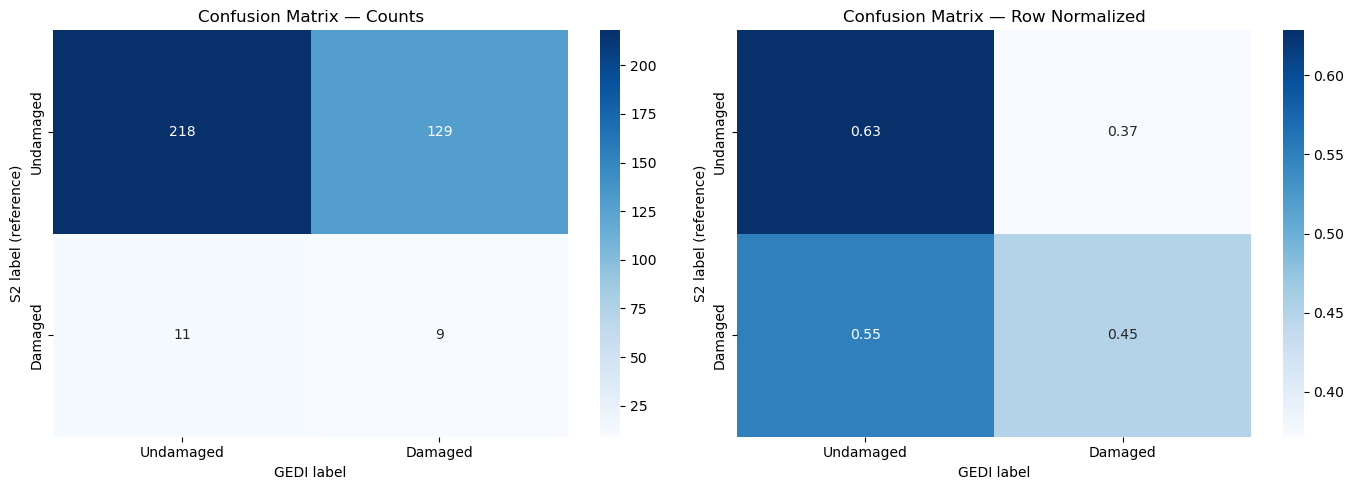

Saved confusion_matrix.png


In [10]:
# ── Confusion matrix ──────────────────────────────────────────────────────────
# S2 = reference (rows), GEDI = prediction (columns)
cm      = confusion_matrix(df["s2_binary"], df["gedi_binary"])
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Undamaged","Damaged"],
            yticklabels=["Undamaged","Damaged"],
            ax=axes[0])
axes[0].set_xlabel("GEDI label")
axes[0].set_ylabel("S2 label (reference)")
axes[0].set_title("Confusion Matrix — Counts")

sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=["Undamaged","Damaged"],
            yticklabels=["Undamaged","Damaged"],
            ax=axes[1])
axes[1].set_xlabel("GEDI label")
axes[1].set_ylabel("S2 label (reference)")
axes[1].set_title("Confusion Matrix — Row Normalized")

plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()
print("Saved confusion_matrix.png")

In [11]:
# ── Classification report ─────────────────────────────────────────────────────
print("Classification Report (S2 = reference, GEDI = prediction):")
print(classification_report(
    df["s2_binary"],
    df["gedi_binary"],
    target_names=["Undamaged", "Damaged"]
))

tn, fp, fn, tp = confusion_matrix(df["s2_binary"], df["gedi_binary"]).ravel()
oa = (tp + tn) / (tp + tn + fp + fn)

print(f"Overall Accuracy: {oa:.3f}")
print(f"TP: {tp:,}  TN: {tn:,}  FP: {fp:,}  FN: {fn:,}")

Classification Report (S2 = reference, GEDI = prediction):
              precision    recall  f1-score   support

   Undamaged       0.95      0.63      0.76       347
     Damaged       0.07      0.45      0.11        20

    accuracy                           0.62       367
   macro avg       0.51      0.54      0.44       367
weighted avg       0.90      0.62      0.72       367

Overall Accuracy: 0.619
TP: 9  TN: 218  FP: 129  FN: 11


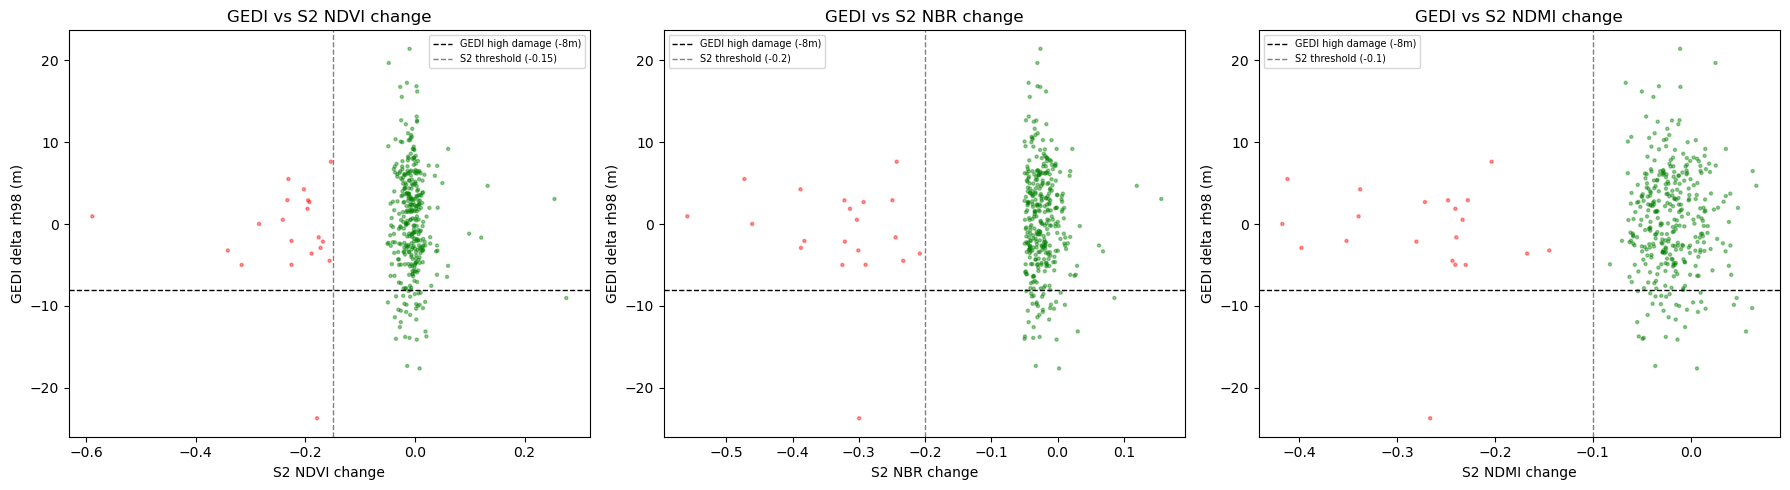

Saved gedi_vs_s2_scatter.png


In [12]:
# ── Scatter plots: GEDI delta_rh98 vs S2 change indices ──────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

colors = df["s2_binary"].map({0: "green", 1: "red"})

for ax, col, threshold, title in zip(
    axes,
    ["NDVI_change", "NBR_change", "NDMI_change"],
    [-0.15, -0.20, -0.10],
    ["NDVI change", "NBR change", "NDMI change"]
):
    ax.scatter(df[col], df["delta_rh98"],
               c=colors, s=5, alpha=0.4)
    ax.axhline(-8,        color="black", linestyle="--",
               linewidth=1, label="GEDI high damage (-8m)")
    ax.axvline(threshold, color="gray",  linestyle="--",
               linewidth=1, label=f"S2 threshold ({threshold})")
    ax.set_xlabel(f"S2 {title}")
    ax.set_ylabel("GEDI delta rh98 (m)")
    ax.set_title(f"GEDI vs S2 {title}")
    ax.legend(fontsize=7)

plt.tight_layout()
plt.savefig("gedi_vs_s2_scatter.png", dpi=150)
plt.show()
print("Saved gedi_vs_s2_scatter.png")

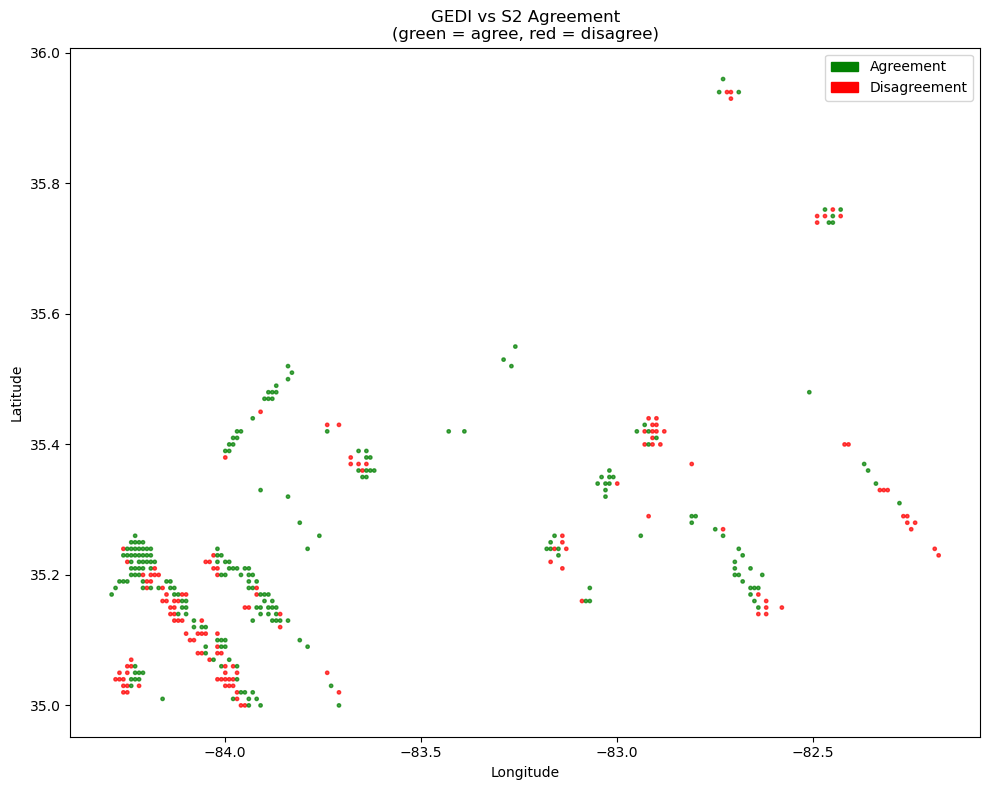

Agreement rate: 61.9%
Saved agreement_map.png


In [13]:
# ── Agreement map ─────────────────────────────────────────────────────────────
gedi_indexed = gedi.reset_index(drop=True)
df_map = df.merge(
    gedi_indexed[["gx", "gy"]].rename_axis("idx").reset_index(),
    on="idx", how="left"
)

df_map["agreement"] = (df_map["gedi_binary"] == df_map["s2_binary"]).astype(int)

color_map = df_map["agreement"].map({1: "green", 0: "red"})

fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(df_map["gx"], df_map["gy"],
           c=color_map, s=6, alpha=0.7)
ax.set_title("GEDI vs S2 Agreement\n(green = agree, red = disagree)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(color="green", label="Agreement"),
    Patch(color="red",   label="Disagreement")
])

plt.tight_layout()
plt.savefig("agreement_map.png", dpi=150)
plt.show()
print(f"Agreement rate: {df_map['agreement'].mean()*100:.1f}%")
print("Saved agreement_map.png")

In [14]:
# ── Save full results ─────────────────────────────────────────────────────────
df_map.to_csv("gedi_s2_comparison.csv", index=False)
print(f"Saved gedi_s2_comparison.csv ({len(df_map):,} rows)")
print("\nDone! All outputs saved.")

Saved gedi_s2_comparison.csv (367 rows)

Done! All outputs saved.
